In [55]:
import os 
import sys 

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report, 
    confusion_matrix,
    ConfusionMatrixDisplay
)
import tensorflow as tf

from google.colab import drive
import shutil
from keras.applications import InceptionV3
from keras.applications.inception_v3 import preprocess_input

import cv2 
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

import random

In [54]:
ROOT_DIR = Path('/home/fangyuan/Projects/Diagnostic-des-tumeurs')

VALID_EXTENSIONS = ('.jpeg' , '.jpg' , '.png' , '.bmp' )
IMG_SIZE = (224, 224)
# DATA = ROOT_DIR / 'data' / 'Data'
DATA = Path('/content/data/data/Data')

DESTINATION_FOLDER = '/content/drive/MyDrive/inception_project/models'
COLAB_BEST_MODEL_PATH = '/content/best_model.keras'
BEST_MODEL_PATH = ROOT_DIR / 'models' 

SEED = 42 
BATCH_SIZE = 32
EPOCHS = 20
LEARNING_RATE = 0.001

In [10]:
# import os
# from google.colab import drive

# if not os.path.ismount("/content/drive"):
#     if os.path.exists("/content/drive"):
#         os.rename("/content/drive", "/content/drive_local_leftover")
#     drive.mount("/content/drive")

# assert os.path.ismount("/content/drive"), "Drive is NOT mounted"
# !ls -la /content/drive/MyDrive/inception_project


# !mkdir -p /content/data
# !unzip -q /content/drive/MyDrive/inception_project/data.zip -d /content/data
!ls /content/data/data/Data

glioma	meningioma  notumor  pituitary


In [14]:
classes = sorted( dir.name for dir in DATA.iterdir() if dir.is_dir() )
class_to_id = { name : id for id, name in enumerate(classes) }
id_to_class = { id : name for name, id in class_to_id.items()}

In [15]:
def load_data(path: Path, classes: list[str] , class_to_id: dict) -> tuple[list[Path], list[int]] : 
    """
    Load the data from the given path and return the paths and labels.
    """
    paths, labels = [], [] 
    for class_name in classes : 
        class_dir = path / class_name   
        for file in class_dir.iterdir() : 
            if file.suffix.lower() in VALID_EXTENSIONS : 
                paths.append(file) 
                labels.append(class_to_id[class_name])
    return paths, labels


In [16]:
def load_image(path, label):
    def _load_image(path_tensor):
        path = path_tensor.numpy().decode("utf-8")

        image = cv2.imread(path)

        if image is None:
            raise FileNotFoundError(
                f"Image not found or cannot be read: {path}"
            )

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, IMG_SIZE)

        image = image.astype(np.float32)

        return image

    image = tf.py_function(
        func=_load_image,
        inp=[path],
        Tout=tf.float32
    )

    image.set_shape([IMG_SIZE[1], IMG_SIZE[0], 3])

    return image, label



def make_data(paths , labels , training=False ) : 
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training : 
        ds = ds.shuffle(10000)

    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)

    ds = ds.batch(BATCH_SIZE)

    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds 




In [17]:
def apply_blur(image, label):
    blurred_image = cv2.GaussianBlur(image, (5, 5), 0)
    return blurred_image, label

def apply_flip(image): 
    flipped_image = cv2.flip(image, 1) # Horizontal flip
    return flipped_image

def apply_noise(image, label):
    # Convert the image to float32 for noise addition
    img_float = image.astype(np.float32)

    # Generate Gaussian noise with mean 0 and standard deviation 10
    noise = np.random.normal(loc=0, scale=10, size=image.shape)
    
    # Add the noise to the image and clip the values to be in the valid range [0, 255] 
    noisy_img = np.clip(img_float + noise, 0, 255).astype(np.uint8)


    # plt.subplot(1, 2, 1)
    # plt.imshow(image)
    # plt.title("Original image")
    # plt.axis("off")

    # plt.subplot(1, 2, 2)
    # plt.imshow(noisy_img)
    # plt.title("Gaussian noise")
    # plt.axis("off")

    # plt.show()

    return noisy_img, label

def augment_data(image, label) : 
    """ 
    Apply data augmentation techniques to the image and return the augmented image and label.
    """
    transformations = [apply_blur, apply_flip, apply_noise] 
    chosen_transformation = random.choice(transformations) 
    return chosen_transformation(image, label)

In [18]:
data_paths, data_labels = load_data(DATA, classes, class_to_id)

<Axes: ylabel='count'>

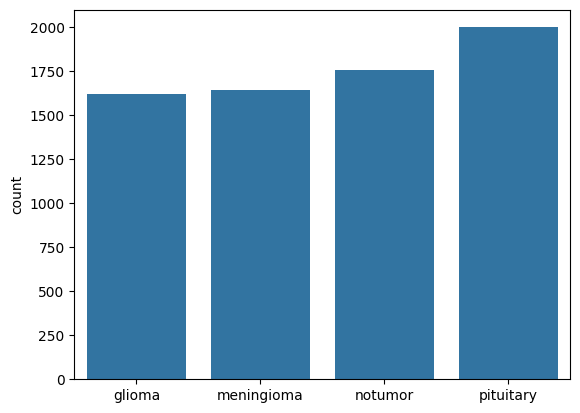

In [19]:
sns.barplot(x=classes, y=pd.Series(data_labels).value_counts().sort_index().sort_values(ascending=True))

ValueError: Attempt to convert a value (PosixPath('/content/data/data/Data/notumor/Tr-no_0296.jpg')) with an unsupported type (<class 'pathlib._local.PosixPath'>) to a Tensor.

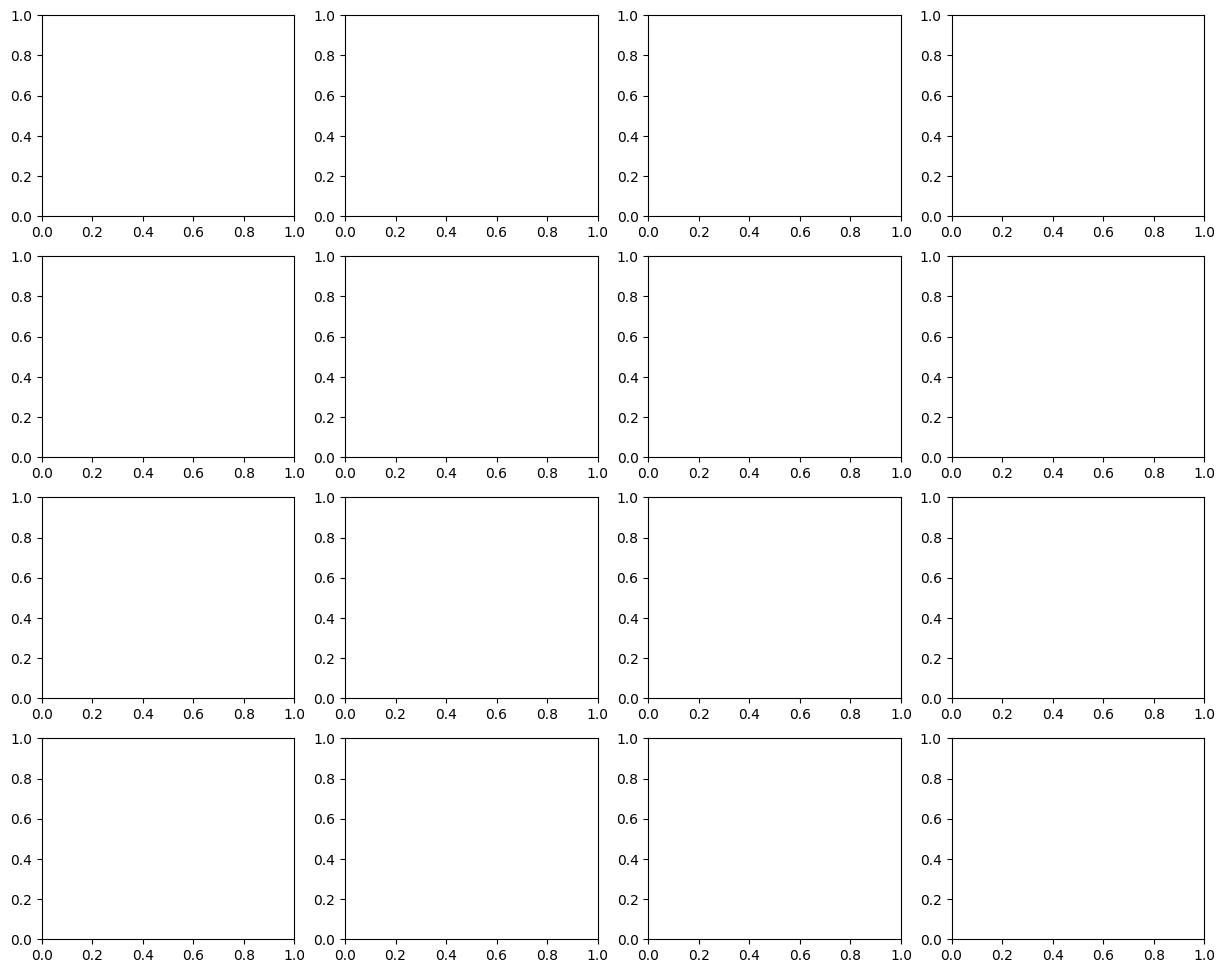

In [20]:
fig , axes = plt.subplots(4, 4, figsize=(15, 12))

for id , label in enumerate(pd.Series(data_labels).value_counts().index) :
    label_images = [data_paths[j] for j in range(len(data_labels)) if data_labels[j] == label]

    for i in range(4) : 
        image, _ = load_image(label_images[i], label)
        if image is not None : 
            axes[id, i].imshow(image)
            axes[id, i].set_title(f"Class: {classes[label]}")
            axes[id, i].axis('off')



In [21]:
X_train, X_temp, y_train, y_temp = train_test_split(
    data_paths,
    data_labels, 
    test_size=0.3, 
    random_state=SEED, 
    stratify=data_labels
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    random_state=SEED,
    stratify=y_temp
)

X_train = [str(path) for path in X_train]
Y_train = [str(path) for path in y_train]

X_val = [str(path) for path in X_val]
Y_val = [str(path) for path in y_val]

X_test = [str(path) for path in X_test]
Y_test = [str(path) for path in y_test]

In [22]:
print(f"Training set: {len(X_train)} images")
print(f"Validation set: {len(X_val)} images")
print(f"Test set: {len(X_test)} images")

Training set: 4916 images
Validation set: 1053 images
Test set: 1054 images


In [23]:
print(classes)
print(pd.Series(y_train).value_counts().sort_index().sort_values(ascending=True))
print(class_to_id)


['glioma', 'meningioma', 'notumor', 'pituitary']
0    1135
1    1151
3    1230
2    1400
Name: count, dtype: int64
{'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


In [24]:
counts = pd.Series(y_train).value_counts()
counts.index = counts.index.map(id_to_class)

Text(0.5, 0, 'Classes')

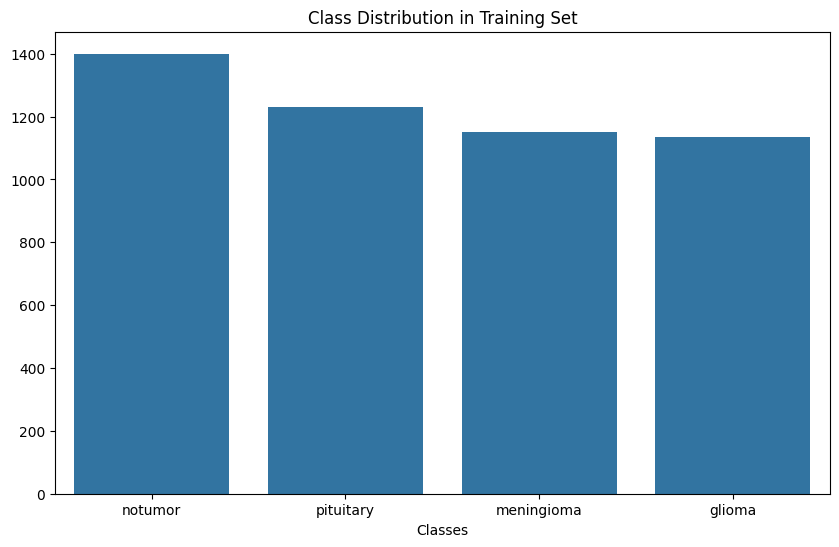

In [25]:
plt.figure(figsize=(10, 6))

sns.barplot(x=counts.index, y=counts.values)
plt.title("Class Distribution in Training Set")
plt.xlabel("Classes")

In [26]:
base_model = InceptionV3(
    weights='imagenet', 
    include_top=False , 
    input_shape=IMG_SIZE + (3,)
)
base_model.summary()

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "inception_v3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 111, 111,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 111, 111,  │         96 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 111, 111,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 109, 109,  │      9,216 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 109, 109,  │         96 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 109, 109,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 109, 109,  │     18,432 │ activation_1[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 109, 109,  │        192 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 109, 109,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 54, 54,    │          0 │ activation_2[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 54, 54,    │      5,120 │ max_pooling2d[0]… │
│                     │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 54, 54,    │        240 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 54, 54,    │          0 │ batch_normalizat… │
│ (Activation)        │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 52, 52,    │    138,240 │ activation_3[0][… │
│                     │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 52, 52,    │        576 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 52, 52,    │          0 │ batch_normalizat

 Total params: 21,802,784 (83.17 MB)

 Trainable params: 21,768,352 (83.04 MB)

 Non-trainable params: 34,432 (134.50 KB)

In [27]:
base_model.trainable = False

Input = tf.keras.Input(shape=IMG_SIZE + (3,))

x = preprocess_input(Input)

x = base_model(x, training=False)

x = tf.keras.layers.GlobalAveragePooling2D()(x)

x = tf.keras.layers.Dense(256, activation='relu')(x)

x = tf.keras.layers.Dropout(0.5)(x)

x = tf.keras.layers.Dense(len(classes), activation='softmax')(x)

model = tf.keras.Model(inputs=Input, outputs=x)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_v3 (Functional)       │ (None, 5, 5, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,328,356 (85.18 MB)

 Trainable params: 525,572 (2.00 MB)

 Non-trainable params: 21,802,784 (83.17 MB)

In [28]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [29]:
train_ds = make_data(X_train, y_train, training=True)
val_ds = make_data(X_val, y_val, training=False)

In [ ]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=BEST_MODEL_PATH,
        monitor="val_loss",
        save_best_only=True
    )
]

In [31]:
history = model.fit(
    train_ds, 
    validation_data=val_ds, 
    epochs=EPOCHS, 
    callbacks=callbacks
)

Epoch 1/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 64s 297ms/step - accuracy: 0.7325 - loss: 0.6936 - val_accuracy: 0.8424 - val_loss: 0.4144 - learning_rate: 0.0010
Epoch 2/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 24s 156ms/step - accuracy: 0.8316 - loss: 0.4485 - val_accuracy: 0.8841 - val_loss: 0.3326 - learning_rate: 0.0010
Epoch 3/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 24s 156ms/step - accuracy: 0.8564 - loss: 0.3767 - val_accuracy: 0.8917 - val_loss: 0.3047 - learning_rate: 0.0010
Epoch 4/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 24s 153ms/step - accuracy: 0.8849 - loss: 0.3127 - val_accuracy: 0.8908 - val_loss: 0.3107 - learning_rate: 0.0010
Epoch 5/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 24s 156ms/step - accuracy: 0.8936 - loss: 0.2908 - val_accuracy: 0.8575 - val_loss: 0.3424 - learning_rate: 0.0010
Epoch 6/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 25s 163ms/step - accuracy: 0.9146 - loss: 0.2308 - val_accuracy: 0.9155 - val_loss: 0.2509 - learning_rate: 2.0000e-04
Epoch 7/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 25s 161ms/step - accuracy:

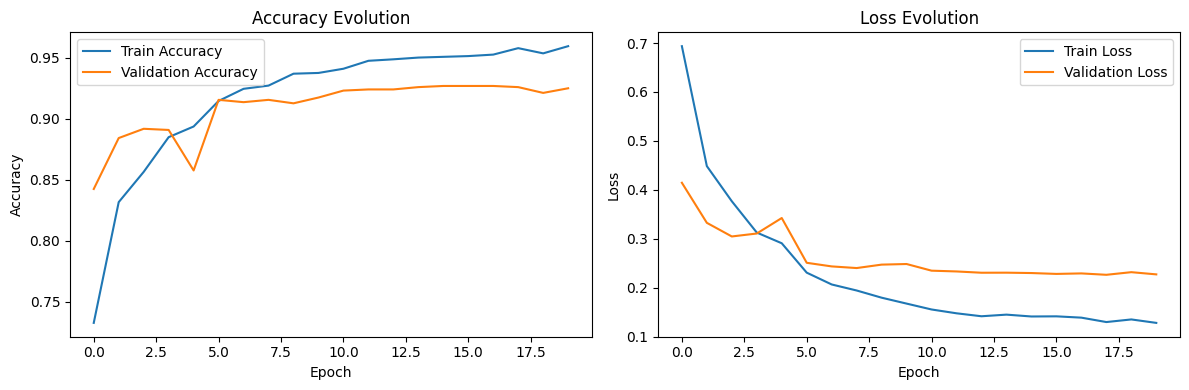

In [32]:

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy Evolution")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss Evolution")
plt.legend()

plt.tight_layout()
plt.show()

In [33]:
test_ds = make_data(X_test, y_test, training=False)
y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model(images, training=False)
 

    predicted_classes = tf.argmax(
        predictions, axis=1
    ).numpy()

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_classes)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

In [34]:
accuracy = accuracy_score(y_true, y_pred)

print("Accuracy:", round(accuracy, 4))

print("Classification Report:\n")

print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(classes)),
    target_names=classes,
    digits=4,
    zero_division=0
))

Accuracy: 0.908
Classification Report:

              precision    recall  f1-score   support

      glioma     0.9138    0.8724    0.8926       243
  meningioma     0.8110    0.8340    0.8224       247
     notumor     0.9764    0.9667    0.9715       300
   pituitary     0.9188    0.9432    0.9308       264

    accuracy                         0.9080      1054
   macro avg     0.9050    0.9041    0.9043      1054
weighted avg     0.9088    0.9080    0.9082      1054



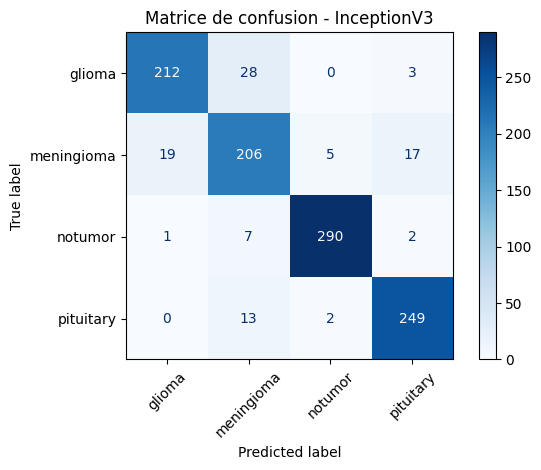

In [35]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(classes))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

disp.plot(xticks_rotation=45, cmap="Blues")
plt.title("Matrice de confusion - InceptionV3")
plt.tight_layout()
plt.show()

In [56]:
os.makedirs(DESTINATION_FOLDER, exist_ok=True)

shutil.copy2(
    COLAB_BEST_MODEL_PATH,
    os.path.join(DESTINATION_FOLDER, 'best_model.keras')
)

'/content/drive/MyDrive/inception_project/models/best_model.keras'